In [7]:
import csv
import math
from dataclasses import dataclass
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

ROOT = Path.cwd().resolve()
if not (ROOT / "configs" / "base_akf.yaml").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.crop_dataloader import SRC_H, SRC_W, _crop
from models.detection.cnn_detector.model import CNNDetector
from models.ssm.base_akf.model import SSM
from models.ssm.base_akf.track import gate, inside

GAME, CLIP = "game1", "Clip1"
START, COUNT = "0138.jpg", 12

# "cnn" measures from the heatmap. "dsp" returns the same object but is not wired yet.
DETECTOR = "cnn"
# "search" tiles the frame until the CNN locks. "label" starts from the first visible label.
INIT = "search"

CONF_MIN = 0.60
# Pixels at or above this fraction of the peak form the Gaussian used for position and spread.
PEAK_FRAC = 0.30
# The CNN crop starts at MIN_SIDE and grows by SIDE_STEP until MAX_SIDE.
# A frame is a miss only when the largest crop also has no ball.
# The red box in the plot is the AKF gate. It is not this crop, and it is not clamped.
MIN_SIDE, SIDE_STEP, MAX_SIDE, MULTIPLE = 48, 48, 720, 4
R_MIN, R_MAX = 2.0, 40.0
MODEL_DIR = "models/detection/cnn_detector/saved_models/cnn_detector"

with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    cfg["paths"]["dataset"] = str((ROOT / dataset).resolve())

run_dir = Path(MODEL_DIR)
if not run_dir.is_absolute():
    run_dir = ROOT / run_dir
with (run_dir / "config.yaml").open() as f:
    cnn_cfg = yaml.safe_load(f)
num_diffs = int(cnn_cfg["model"]["num_diffs"])

VISIBILITY = {0: "not in frame", 1: "visible", 2: "hard to see", 3: "occluded"}
MOVEMENT = {0: "flying", 1: "hit", 2: "bouncing"}


@dataclass
class Meas:
    """One detector reading. ``xy`` is None when the detector does not fire.

    ``spread`` is the mean Gaussian sigma in source pixels. ``spread_x`` and
    ``spread_y`` are the two axes, so the std function can switch to the wider one.
    """

    xy: np.ndarray | None
    spread: float
    spread_x: float
    spread_y: float
    conf: float
    heat: np.ndarray | None = None
    origin: tuple[int, int] | None = None
    side: int | None = None


def measurement_std(spread: float) -> float:
    """Heatmap sigma (source pixels) -> measurement std passed to the AKF.

    ``spread`` is ``sqrt(0.5 * (spread_x**2 + spread_y**2))``. To trust the wider
    axis instead, pass ``max(meas.spread_x, meas.spread_y)`` from ``_apply``.
    """
    if not np.isfinite(spread):
        return R_MAX
    return float(np.clip(spread, R_MIN, R_MAX))


def spike_filter(ssm: SSM, meas: Meas) -> None:
    """Extra uncertainty after predict and before update.

    Misses already grow ``P`` inside ``update(None)``. A bump here is part of this
    update; whatever survives widens the next gate.
    """
    # if meas.xy is None:
    #     ssm.P[0, 0] += 25.0 ** 2
    #     ssm.P[1, 1] += 25.0 ** 2
    # if np.isfinite(meas.spread) and meas.spread > 12.0:
    #     ssm.P[0, 0] += meas.spread ** 2
    #     ssm.P[1, 1] += meas.spread ** 2
    #     ssm.scale = min(ssm.scale * 2.0, ssm.q_max)
    return


def _miss() -> Meas:
    return Meas(None, float("nan"), float("nan"), float("nan"), float("nan"))


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = Path(cfg["paths"]["dataset"]) / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            vis = int(row["visibility"] or 0)
            xy = None
            if vis > 0:
                xy = np.array(
                    [float(row["x-coordinate"]), float(row["y-coordinate"])],
                    dtype=np.float64,
                )
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "visibility": vis,
                    "status": int(row["status"] or 0),
                    "xy": xy,
                }
            )
    return frames


def read_gray(path: Path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
        gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return gray


def frame_diffs(grays: list[np.ndarray], i: int) -> list[np.ndarray] | None:
    if i < num_diffs:
        return None
    window = grays[i - num_diffs : i + 1]
    return [
        (window[k].astype(np.float32) - window[k - 1].astype(np.float32)) / 255.0
        for k in range(1, len(window))
    ]


def _ladder() -> list[int]:
    """Crop sides from ``MIN_SIDE`` up to ``MAX_SIDE``, inclusive."""
    limit = max(MIN_SIDE, min(MAX_SIDE, max(SRC_W, SRC_H)))
    side = MIN_SIDE
    sides = [side]
    step = max(SIDE_STEP, MULTIPLE)
    while side < limit:
        side = min(limit, side + step)
        if side != sides[-1]:
            sides.append(side)
    return sides


def decode(heat: np.ndarray) -> Meas:
    conf = float(heat.max()) if heat.size else 0.0
    if conf < CONF_MIN:
        return Meas(None, float("nan"), float("nan"), float("nan"), conf)
    ys, xs = np.nonzero(heat >= PEAK_FRAC * conf)
    weight = heat[ys, xs].astype(np.float64)
    weight /= weight.sum()
    mx = float(xs @ weight)
    my = float(ys @ weight)
    var_x = float(((xs - mx) ** 2) @ weight)
    var_y = float(((ys - my) ** 2) @ weight)
    return Meas(
        np.array([mx, my], dtype=np.float64),
        math.sqrt(max(0.0, 0.5 * (var_x + var_y))),
        math.sqrt(max(var_x, 0.0)),
        math.sqrt(max(var_y, 0.0)),
        conf,
    )


def _stack(diffs: list[np.ndarray], x0: int, y0: int, side: int) -> np.ndarray:
    return np.stack([_crop(d, x0, y0, side, side) for d in diffs], axis=0)


def _forward(crops: list[np.ndarray]) -> np.ndarray:
    batch = torch.from_numpy(np.stack(crops)).to(device)
    with torch.inference_mode():
        return model(batch)[:, 0].detach().cpu().numpy()


def _axis_origins(lo: float, hi: float, side: int, frame: int) -> list[int]:
    lo_i = max(0, int(math.floor(lo)))
    hi_i = min(frame, int(math.ceil(hi)))
    last = max(0, frame - side)
    if hi_i <= lo_i:
        return [0]
    if hi_i - lo_i <= side:
        origin = lo_i + (hi_i - lo_i - side) // 2
        return [min(max(0, origin), last)]
    stride = max(MULTIPLE, side // 2)
    first = min(max(0, lo_i), last)
    end = min(max(0, hi_i - side), last)
    if end < first:
        first, end = end, first
    origins = list(range(first, end + 1, stride))
    if origins[-1] != end:
        origins.append(end)
    return origins


def _search_origins(side: int, box=None) -> list[tuple[int, int]]:
    if box is None:
        box = (0.0, 0.0, float(SRC_W), float(SRC_H))
    xs = _axis_origins(box[0], box[2], side, SRC_W)
    ys = _axis_origins(box[1], box[3], side, SRC_H)
    return [(x, y) for y in ys for x in xs]


def _search(diffs: list[np.ndarray], *, keep_heat: bool, box=None) -> Meas:
    """Best peak on ``MAX_SIDE`` tiles. ``box`` limits the tiles and the peak."""
    origins = _search_origins(MAX_SIDE, box)
    best: Meas | None = None
    best_conf = -1.0
    low_conf = float("nan")
    for start in range(0, len(origins), 16):
        chunk = origins[start : start + 16]
        heats = _forward([_stack(diffs, x0, y0, MAX_SIDE) for x0, y0 in chunk])
        for (x0, y0), heat in zip(chunk, heats):
            meas = decode(heat)
            if meas.xy is None:
                if not np.isfinite(low_conf) or meas.conf > low_conf:
                    low_conf = float(meas.conf)
                continue
            meas.xy = meas.xy + np.array([x0, y0], dtype=np.float64)
            if box is not None and not inside(meas.xy, box):
                continue
            if meas.conf <= best_conf:
                continue
            if keep_heat:
                meas.heat = heat
                meas.origin = (x0, y0)
            best = meas
            best_conf = meas.conf
    if best is not None:
        return best
    missed = _miss()
    missed.conf = low_conf
    return missed


def measure_cnn(diffs, pred, box, *, keep_heat: bool) -> Meas:
    """Grow one crop around the prediction until the ball appears or the crop is maxed.

    A smaller crop with no peak is not a miss. The frame fails only after ``MAX_SIDE``.
    With no prediction yet, tile the whole image once to get the first lock.
    """
    if pred is None:
        return _search(diffs, keep_heat=keep_heat)
    missed = _miss()
    for side in _ladder():
        x0 = int(round(float(pred[0]) - side / 2))
        y0 = int(round(float(pred[1]) - side / 2))
        heat = _forward([_stack(diffs, x0, y0, side)])[0]
        meas = decode(heat)
        meas.side = side
        if keep_heat:
            meas.heat = heat
            meas.origin = (x0, y0)
        if meas.xy is None:
            if not np.isfinite(missed.conf) or meas.conf >= missed.conf:
                missed = meas
            continue
        meas.xy = meas.xy + np.array([x0, y0], dtype=np.float64)
        return meas
    return missed


def measure_dsp(diffs, pred, box, *, keep_heat: bool) -> Meas:
    raise NotImplementedError(
        "DSP measurement is not wired yet; see notebooks/test_dsp_detector.ipynb"
    )


def measure(diffs, pred, box, *, keep_heat: bool = False) -> Meas:
    if DETECTOR == "cnn":
        return measure_cnn(diffs, pred, box, keep_heat=keep_heat)
    if DETECTOR == "dsp":
        return measure_dsp(diffs, pred, box, keep_heat=keep_heat)
    raise ValueError(f"unknown detector {DETECTOR!r}")


def _record(ssm: SSM, pred, box, z, meas: Meas, r_std: float) -> dict:
    return {
        "pred": None if pred is None else np.asarray(pred, dtype=np.float64).copy(),
        "post": ssm.mean[:2].copy(),
        "box": box,
        "z": None if z is None else np.asarray(z, dtype=np.float64).copy(),
        "spread": float(meas.spread),
        "spread_x": float(meas.spread_x),
        "spread_y": float(meas.spread_y),
        "r_std": float(r_std),
        "conf": float(meas.conf),
        "scale": float(ssm.scale),
        "heat": meas.heat,
        "origin": meas.origin,
        "side": meas.side,
    }


def _apply(ssm: SSM, meas: Meas) -> tuple[np.ndarray | None, float]:
    # A peak is a measurement. The crop already grew to MAX_SIDE before this is None.
    # Mean sigma. Use max(meas.spread_x, meas.spread_y) for the wider axis.
    r_std = measurement_std(meas.spread) if meas.xy is not None else float("nan")
    spike_filter(ssm, meas)
    ssm.update(meas.xy, None if meas.xy is None else r_std)
    return meas.xy, r_std


def run_clip(frames: list[dict], *, keep: set[int] | None = None) -> list[dict | None]:
    """Predict, crop on the uncertainty frame, measure, then update.

    ``keep`` stores the heatmap for those frame indices.
    """
    keep = keep or set()
    if INIT not in ("search", "label"):
        raise ValueError(f"unknown INIT {INIT!r}")
    grays = [read_gray(frame["path"]) for frame in frames]
    ssm = SSM(cfg["tracker"])
    gate_sigma = float(cfg["tracker"]["gate_sigma"])
    steps: list[dict | None] = []
    for i, frame in enumerate(frames):
        diffs = frame_diffs(grays, i)
        if ssm.mean is None:
            if INIT == "label":
                if frame["xy"] is None:
                    steps.append(None)
                    continue
                ssm.initiate(frame["xy"])
                box = gate(ssm.mean, ssm.cov, gate_sigma)
                steps.append(_record(ssm, None, box, frame["xy"], _miss(), float("nan")))
                continue
            if diffs is None:
                steps.append(None)
                continue
            meas = measure(diffs, None, None, keep_heat=i in keep)
            if meas.xy is None:
                steps.append(None)
                continue
            ssm.initiate(meas.xy)
            box = gate(ssm.mean, ssm.cov, gate_sigma)
            steps.append(
                _record(ssm, None, box, meas.xy, meas, measurement_std(meas.spread))
            )
            continue

        ssm.predict()
        pred = ssm.mean[:2].copy()
        box = gate(ssm.mean, ssm.cov, gate_sigma)
        meas = _miss() if diffs is None else measure(diffs, pred, box, keep_heat=i in keep)
        used, r_std = _apply(ssm, meas)
        steps.append(_record(ssm, pred, box, used, meas, r_std))
    return steps


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNNDetector(in_channels=num_diffs).to(device).eval()
checkpoint = next(run_dir.glob("*.pt"))
state = torch.load(checkpoint, map_location=device, weights_only=True)
model.load_state_dict(state["model"])
print(f"loaded {checkpoint.relative_to(ROOT)}  ({device})  detector={DETECTOR}  init={INIT}")

clip = load_clip(GAME, CLIP)
start = next(i for i, frame in enumerate(clip) if frame["file"] == START)
window = range(start, start + COUNT)
steps = run_clip(clip, keep=set(window))

print(f"{GAME}/{CLIP}  {clip[start]['file']} → {clip[start + COUNT - 1]['file']}")
for i in window:
    frame, step = clip[i], steps[i]
    if step is None:
        print(f"{frame['file']}  no difference")
        continue
    xy = frame["xy"]
    spread = f"{step['spread']:5.1f}" if np.isfinite(step["spread"]) else "    —"
    r_std = f"{step['r_std']:5.1f}" if np.isfinite(step["r_std"]) else "    —"
    conf = f"{step['conf']:4.2f}" if np.isfinite(step["conf"]) else "   —"
    if step["pred"] is None:
        print(f"{frame['file']}  init   spread={spread}  r={r_std}  conf={conf}")
        continue
    err = float(np.hypot(*(step["pred"] - xy))) if xy is not None else float("nan")
    err_txt = f"{err:5.1f}" if np.isfinite(err) else "    —"
    choice = "used" if step["z"] is not None else "miss"
    x0, y0, x1, y1 = step["box"]
    crop = f"{step['side']:4d}" if step["side"] else "   —"
    print(
        f"{frame['file']}  {MOVEMENT[frame['status']]:8}  "
        f"{VISIBILITY[frame['visibility']]:12}  "
        f"pred_err={err_txt}  gate={x1 - x0:5.0f}  crop={crop}  "
        f"spread={spread}  r={r_std}  conf={conf}  scale={step['scale']:5.2f}  {choice}"
    )


loaded models/detection/cnn_detector/saved_models/cnn_detector/cnn_detector.pt  (cuda)  detector=cnn  init=search
game1/Clip1  0138.jpg → 0149.jpg
0138.jpg  flying    visible       pred_err=  4.3  gate=   37  crop=  48  spread=  1.9  r=  2.0  conf=0.61  scale= 1.12  used
0139.jpg  flying    visible       pred_err=  3.8  gate=   37  crop=  96  spread=  2.2  r=  2.2  conf=0.74  scale= 1.10  used
0140.jpg  flying    visible       pred_err=  2.1  gate=   38  crop=  96  spread=  2.0  r=  2.0  conf=0.72  scale= 1.09  used
0141.jpg  hit       visible       pred_err= 53.4  gate=   37  crop=  96  spread=    —  r=    —  conf=0.37  scale= 1.63  miss
0142.jpg  hit       visible       pred_err=108.5  gate=  166  crop= 672  spread=    —  r=    —  conf=0.38  scale= 2.45  miss
0143.jpg  flying    visible       pred_err=149.4  gate=  240  crop= 672  spread=    —  r=    —  conf=0.48  scale= 3.67  miss
0144.jpg  flying    visible       pred_err=190.6  gate=  306  crop= 720  spread=    —  r=    —  conf=0.

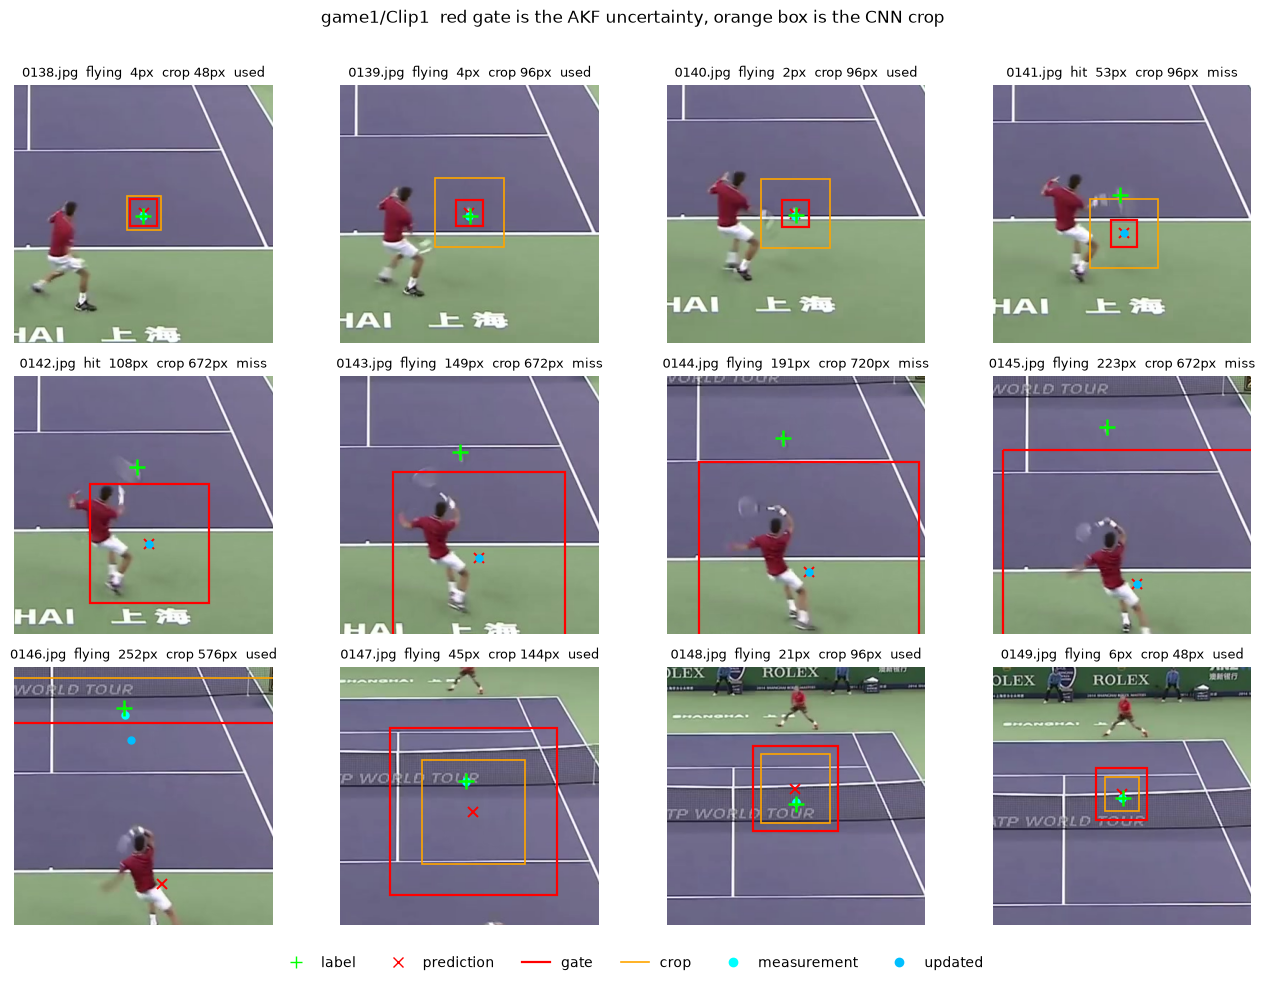

In [8]:
ncols = 4
half = 180
nrows = int(np.ceil(COUNT / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.3 * nrows))
for ax, i in zip(np.atleast_1d(axes).ravel(), window):
    frame, step = clip[i], steps[i]
    bgr = cv2.imread(str(frame["path"]), cv2.IMREAD_COLOR)
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    if step is None:
        ax.set_title(f"{frame['file']}  no difference", fontsize=9)
        ax.axis("off")
        continue
    heat, origin = step["heat"], step["origin"]
    if heat is not None and origin is not None:
        x0, y0 = origin
        h, w = heat.shape
        rgba = plt.colormaps["magma"](np.clip(heat, 0.0, 1.0))
        rgba[..., 3] = np.clip(heat, 0.0, 1.0)
        ax.imshow(
            rgba,
            extent=(x0 - 0.5, x0 + w - 0.5, y0 + h - 0.5, y0 - 0.5),
        )
    if step["origin"] is not None and step["side"]:
        cx, cy = step["origin"]
        ax.add_patch(
            Rectangle((cx, cy), step["side"], step["side"], fill=False, edgecolor="orange", lw=1.2)
        )
    x0, y0, x1, y1 = step["box"]
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", lw=1.6))
    if step["pred"] is not None:
        ax.plot(*step["pred"], "x", color="red", ms=7, mew=1.4)
    ax.plot(*step["post"], "o", color="deepskyblue", ms=5)
    if step["z"] is not None:
        ax.plot(*step["z"], "o", color="cyan", ms=5)
    xy = frame["xy"]
    if xy is not None:
        ax.plot(*xy, "+", color="lime", ms=11, mew=1.8)
        center = xy if step["pred"] is None else 0.5 * (step["pred"] + xy)
    else:
        center = step["post"]
    ax.set_xlim(center[0] - half, center[0] + half)
    ax.set_ylim(center[1] + half, center[1] - half)
    title = frame["file"]
    if step["pred"] is not None and xy is not None:
        err = float(np.hypot(*(step["pred"] - xy)))
        tag = "used" if step["z"] is not None else "miss"
        crop = f"{step['side']}px" if step["side"] else "—"
        title += f"  {MOVEMENT[frame['status']]}  {err:.0f}px  crop {crop}  {tag}"
    elif step["pred"] is None:
        title += "  init"
    ax.set_title(title, fontsize=9)
    ax.axis("off")

for ax in np.atleast_1d(axes).ravel()[COUNT:]:
    ax.axis("off")

fig.legend(
    handles=[
        Line2D([0], [0], marker="+", color="lime", lw=0, ms=8, label="label"),
        Line2D([0], [0], marker="x", color="red", lw=0, ms=7, label="prediction"),
        Line2D([0], [0], color="red", lw=1.6, label="gate"),
        Line2D([0], [0], color="orange", lw=1.2, label="crop"),
        Line2D([0], [0], marker="o", color="cyan", lw=0, ms=6, label="measurement"),
        Line2D([0], [0], marker="o", color="deepskyblue", lw=0, ms=6, label="updated"),
    ],
    loc="lower center",
    ncol=6,
    frameon=False,
)
fig.suptitle(f"{GAME}/{CLIP}  red gate is the AKF uncertainty, orange box is the CNN crop", fontsize=12)
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()


In [9]:
misses = weak = false = 0
errs, used, visibility, movement = [], [], [], []
spreads, rstds = [], []
for game in cfg["splits"]["test"]:
    game_dir = Path(cfg["paths"]["dataset"]) / game
    for clip_dir in sorted(p for p in game_dir.iterdir() if p.is_dir()):
        frames = load_clip(game, clip_dir.name)
        traced = run_clip(frames)
        for frame, step in zip(frames, traced):
            xy = frame["xy"]
            if step is None or step["post"] is None:
                if frame["visibility"] == 0:
                    misses += 1
                    if step is not None and step["z"] is not None:
                        false += 1
                continue
            if xy is None:
                misses += 1
                if step["z"] is not None:
                    false += 1
                continue
            errs.append(float(np.hypot(*(step["post"] - xy))))
            used.append(step["z"] is not None)
            visibility.append(frame["visibility"])
            movement.append(frame["status"])
            spreads.append(step["spread"])
            rstds.append(step["r_std"])
            if step["z"] is None:
                weak += 1

errs = np.asarray(errs)
used = np.asarray(used)
visibility = np.asarray(visibility)
movement = np.asarray(movement)
spreads = np.asarray(spreads, dtype=np.float64)
rstds = np.asarray(rstds, dtype=np.float64)


def _mean(values: np.ndarray) -> str:
    values = values[np.isfinite(values)]
    return f"{values.mean():5.1f}" if len(values) else "    —"


def show_group(name: str, mask: np.ndarray) -> None:
    count = int(mask.sum())
    if count == 0:
        return
    print(
        f"{name:16}  n={count:5d}  "
        f"dist={errs[mask].mean():6.1f}  "
        f"used={used[mask].mean():.3f}  "
        f"spread={_mean(spreads[mask])}  "
        f"r={_mean(rstds[mask & used])}"
    )


print(
    "test  dist = prediction error (px)  used = fraction where a crop found the ball  "
    "spread = heatmap sigma  r = measurement std on accepted frames"
)
show_group("all", np.ones(len(errs), dtype=bool))
print("movement")
for code, name in MOVEMENT.items():
    show_group(f"  {name}", movement == code)
print("obscurity")
print(f"{'  not in frame':16}  n={misses:5d}  false={false:5d}  accepted with no label")
print(f"{'  no detection':16}  n={weak:5d}  label present, no ball up to {MAX_SIDE}px")
for code, name in VISIBILITY.items():
    if code == 0:
        continue
    show_group(f"  {name}", visibility == code)


test  dist = prediction error (px)  used = fraction where a crop found the ball  spread = heatmap sigma  r = measurement std on accepted frames
all               n= 2047  dist=   7.4  used=0.894  spread=  2.7  r=  2.7
movement
  flying          n= 1944  dist=   7.3  used=0.904  spread=  2.7  r=  2.7
  hit             n=   47  dist=  18.4  used=0.383  spread=  6.0  r=  6.3
  bouncing        n=   56  dist=   3.0  used=0.982  spread=  2.1  r=  2.4
obscurity
  not in frame    n=   62  false=    2  accepted with no label
  no detection    n=  216  label present, no ball up to 720px
  visible         n= 1868  dist=   7.4  used=0.923  spread=  2.7  r=  2.7
  hard to see     n=  178  dist=   7.8  used=0.596  spread=  3.4  r=  3.2
  occluded        n=    1  dist=   4.7  used=0.000  spread=    —  r=    —


In [ ]:





#Post 
test  dist = prediction error (px)  used = fraction where a crop found the ball  spread = heatmap sigma  r = measurement std on accepted frames
all               n= 2058  dist=  10.0  used=0.973  spread=  3.5  r=  3.2
movement
  flying          n= 1953  dist=   9.2  used=0.977  spread=  3.4  r=  3.2
  hit             n=   48  dist=  34.0  used=0.792  spread= 10.8  r=  8.7
  bouncing        n=   57  dist=  15.3  used=0.965  spread=  1.7  r=  2.0
obscurity
  not in frame    n=   62  false=   17  accepted with no label
  no detection    n=   56  label present, no ball up to 720px
  visible         n= 1875  dist=   8.9  used=0.986  spread=  3.4  r=  3.2
  hard to see     n=  182  dist=  21.6  used=0.841  spread=  4.5  r=  3.8
  occluded        n=    1  dist=   1.0  used=0.000  spread=    —  r=    —

# Base AKF
test  dist = prediction error (px)  used = fraction where a crop found the ball  spread = heatmap sigma  r = measurement std on accepted frames
all               n= 2046  dist=  13.5  used=0.973  spread=  3.1  r=  3.1
movement
  flying          n= 1942  dist=  12.6  used=0.977  spread=  3.0  r=  3.0
  hit             n=   48  dist=  35.6  used=0.792  spread= 10.8  r=  8.7
  bouncing        n=   56  dist=  26.0  used=0.964  spread=  1.7  r=  2.0
obscurity
  not in frame    n=   62  false=   17  accepted with no label
  no detection    n=   56  label present, no ball up to 720px
  visible         n= 1863  dist=  12.5  used=0.986  spread=  2.9  r=  3.0
  hard to see     n=  182  dist=  24.0  used=0.841  spread=  4.5  r=  3.8
  occluded        n=    1  dist=   1.0  used=0.000  spread=    —  r=    —